# Application and Information Layer: Apps, Connections, Converters & Info Items
*Fabian Nütz*

The logical layer models **end-to-end communication** on top of the physical network. In this notebook you will:

- Create apps on devices
- Define connections between apps with protocols and information items
- Understand the `peers` / `producer` data-flow model
- Model protocol converters with chained connections
- Check whether a connection is topologically feasible
- Visualize the logical layer graph

## Setup — recreate the physical network from notebook 02

In [1]:
import pandaict as pi
from pandaict.utils.enums import NodeType, DeviceType, AppType, InfoItem
from pandaict.plot import create_plot
import matplotlib.pyplot as plt

net = pi.create_empty_network(name='Logical Layer Demo')

# Physical layer (same as notebook 02, condensed)
n_core  = pi.create_ict_node(net, name='Core-Router',   node_type=NodeType.ROUTER, link_types=['Fiber','LAN1000'])
n_sw1   = pi.create_ict_node(net, name='Switch-1',      node_type=NodeType.SWITCH, link_types=['LAN1000'])
n_sw2   = pi.create_ict_node(net, name='Switch-2',      node_type=NodeType.SWITCH, link_types=['LAN1000'])
n_field = pi.create_ict_node(net, name='Field-Switch',   node_type=NodeType.SWITCH, link_types=['LAN1000'])

ctrl_server = pi.create_ict_device(net, name='CTRL-Server', device_type=DeviceType.SERVER)
rtu_a       = pi.create_ict_device(net, name='RTU-A',       device_type=DeviceType.RTU)
rtu_b       = pi.create_ict_device(net, name='RTU-B',       device_type=DeviceType.RTU)
mon_dev = pi.create_ict_device(net, name='Monitoring',device_type=DeviceType.SERVER,)

pi.create_ict_link(net, name='L-SW1-Core',   from_elt=n_sw1,        to_elt=[n_core],       link_type='LAN1000')
pi.create_ict_link(net, name='L-Core-SW2',   from_elt=n_core,       to_elt=[n_sw2],        link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Field',  from_elt=n_sw2,        to_elt=[n_field],      link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-SW1',  from_elt=n_field,      to_elt=[n_sw1],        link_type='LAN1000')
pi.create_ict_link(net, name='L-Core-CTRL',  from_elt=n_core,       to_elt=[ctrl_server],  link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-RTU-A',from_elt=n_field,      to_elt=[rtu_a],        link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-RTU-B',from_elt=n_field,      to_elt=[rtu_b],        link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Mon',    from_elt=n_sw2,        to_elt=[mon_dev],      link_type='LAN1000')

print('Physical layer ready:', len(net.node), 'nodes,', len(net.device), 'devices,', len(net.link), 'links')

Physical layer ready: 4 nodes, 4 devices, 8 links


Next, we'll extend this network by the application and information layers. This will result in the following network. 

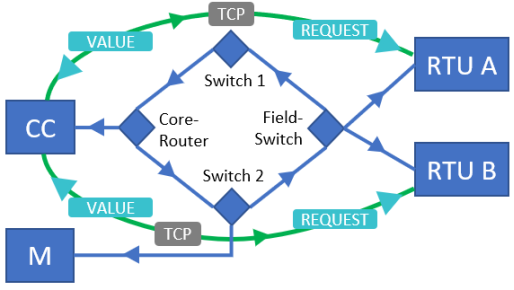

The green lines show connections on the application layer. Again, the green arrows point into the "downstream" direction of the connections. Apps are not shown. Shown in cyan are information items travelling over the connections. They define the information layer. In this case, the cyan arrows point into the direction of information flow. 


## Apps

An **app** is a service running on a device. Each app belongs to exactly one device. Built-in types include:

- `AppType.CLIENT` — initiates requests
- `AppType.WEBSERVER` — serves responses
- `AppType.CONVERTER` — translates between two protocols (requires DeviceType.CONVERTER)
- `AppType.FILESERVER`, `AppType.RESTSERVER`, `AppType.RESTCLIENT`

Key parameters: `name`, `app_type`, `device` (the device id the app runs on).

In [2]:
# Apps on the existing devices
app_ctrl = pi.create_ict_app(net, name='App-CTRL',  app_type=AppType.CLIENT,    device=ctrl_server)
app_rtua = pi.create_ict_app(net, name='App-RTU-A', app_type=AppType.WEBSERVER, device=rtu_a)
app_rtub = pi.create_ict_app(net, name='App-RTU-B', app_type=AppType.WEBSERVER, device=rtu_b)

display(net.app[['name', 'type', 'device']])

,name,type,device
0,App-CTRL,AppType.CLIENT,0
1,App-RTU-A,AppType.WEBSERVER,1
2,App-RTU-B,AppType.WEBSERVER,2


## Connections

A **connection** models end-to-end logical communication between two apps using a specific protocol. It transmits one or more `info_items`.

Key parameters:
- `from_app` / `to_app` — app tuples (direction: from → to = downstream)
- `protocol` — string matching a key in `net.std_types['protocol']`
- `info_items` — list of `InfoItem` enums
- `peers` — 2-tuple of app tuples, defining who the communicating parties are
- `producer` — list of indices (0 or 1) into `peers`, indicating who *originates* each `info_item`

### A simple connection: CTRL server requests data from RTU-A

In [3]:
conn_rtua = pi.create_ict_connection(net, name='CTRL-to-RTU-A',
                                     from_app=app_ctrl, to_app=app_rtua,
                                     protocol='TCP',
                                     info_items=[InfoItem.REQUEST, InfoItem.VALUE],
                                     peers=(app_ctrl, app_rtua),
                                     producer=[0, 1],
                                     prod_freq_ms=[1000,1000])

print(f"Connection created: {conn_rtua}")
display(net.conn[['name', 'protocol', 'from', 'to']])

Connection created: ('conn', 0)


,name,protocol,from,to
0,CTRL-to-RTU-A,TCP,0,1


**Understanding `peers` and `producer`**:
- `peers = (app_ctrl, app_rtua)` - the two apps involved
- `info_items = [REQUEST, VALUE]` - what gets transmitted
- `producer = [0, 1]` means:
  - `peers[0]` (which is `app_ctrl`) produces `REQUEST`
  - `peers[1]` (which is `app_rtua`) produces `VALUE`
- `prod_freq_ms = [1000,1000]` means that both defined info_items are produced and sent each second. 
- `producer`, `prod_freq_ms` and `info_items` must have the same length
- Each entry in `producer` and `prod_freq_ms` refer to the entry with the same index in `info_items`
- `producer` only contains zeros and ones, each indicating which of the two peers produces an info item
- `prod_freq_ms` is optional. If left out, the info_item is assumed to be produced event-driven. 

This information is essential for routing: the system must know which direction each data item flows.

## Protocol converters

A converter is a special type of device used to translate between two protocols (e.g., MODBUS-TCP → MODBUS-RS485). In pandaict this is modeled as:
- A device of type `DeviceType.CONVERTER`
- An app of type `AppType.CONVERTER` with a `conversions` list
- A pair of **chained connections**: one on each side of the converter# View the converter's conversions

### How chained connections work

For our example, we design a converter that splits one end-to-end communication into two connections with different protocols:

1. **CTRL-to-Converter** (TCP): the control center app sends a TCP request to the converter app
2. The **converter app** translates TCP to MODBUS-RS485 (defined in its `conversions` list)
3. **Converter-to-RTUB** (MODBUS-RS485): the translated message reaches RTU-B over the RS485 protocol

Both connections share the same `peers` (app_ctrl and app_rtub) and `producer` configuration,
meaning the end-to-end data flow is preserved across the protocol boundary. The `peers` field
tracks who the *real* communicating parties are, not the converter intermediate.


In [4]:
from pandaict.utils.utils import get_elt

# 1. Create a standard type for the RS485 protocol (see notebook 06 for details)
pi.create_std_type(net, {'info_items': [InfoItem.REQUEST, InfoItem.VALUE]},
                   name='MODBUS-RS485', element='protocol')

# 2. Create a converter device and app
(conv_dev, conv_app) = pi.create_ict_devapp(net, name='Proto-Converter',
                                            device_type=DeviceType.CONVERTER,
                                            app_type=AppType.CONVERTER,
                                            conversions=[('TCP', 'MODBUS-RS485', 0.001, 0.001)])

# 3. Cable the converter between Core-Router and RTU-B
link_core_conv = pi.create_ict_link(net, name='L-Core-Conv',  from_elt=n_core,  to_elt=[conv_dev], link_type='LAN1000')
link_conv_rtub = pi.create_ict_link(net, name='L-Conv-RTUB', from_elt=conv_dev, to_elt=[rtu_b],    link_type='LAN1000')

# 4. Create CHAINED connections through the converter
#    CTRL --> Converter (TCP)     +     Converter --> RTU-B (MODBUS-RS485)
conn_ctrl_conv = pi.create_ict_connection(net, name='CTRL-to-Converter',
    from_app=app_ctrl, to_app=conv_app, protocol='TCP',
    info_items=[InfoItem.REQUEST, InfoItem.VALUE],
    peers=(app_ctrl, app_rtub), producer=[0, 1])

conn_conv_rtub = pi.create_ict_connection(net, name='Converter-to-RTUB',
    from_app=conv_app, to_app=app_rtub, protocol='MODBUS-RS485',
    info_items=[InfoItem.REQUEST, InfoItem.VALUE],
    peers=(app_ctrl, app_rtub), producer=[0, 1])

print(f'Chained connections: {conn_ctrl_conv} --> {conn_conv_rtub}')
print(f'Protocols: {get_elt(net, conn_ctrl_conv)["protocol"]} --> {get_elt(net,conn_conv_rtub)["protocol"]}')

Chained connections: ('conn', 1) --> ('conn', 2)
Protocols: TCP --> MODBUS-RS485


In [5]:
# View the converter's conversions and the chained connections
display(net.app[net.app['type'] == AppType.CONVERTER][['name', 'type', 'device', 'conversions']])
print("\nAll connections:")
display(net.conn[['name', 'protocol', 'from', 'to']])

,name,type,device,conversions
3,Proto-Converter,AppType.CONVERTER,4,"[(TCP, MODBUS-RS485, 0.001, 0.001)]"



All connections:


,name,protocol,from,to
0,CTRL-to-RTU-A,TCP,0,1
1,CTRL-to-Converter,TCP,0,3
2,Converter-to-RTUB,MODBUS-RS485,3,2


## Checking connectivity

`is_connection_possible()` checks whether a path exists through the physical layer for a given connection. It returns a 2-tuple of booleans indicating downstream and upstream connectivity. Note that in case of a chained connection, peer apps can only communicate when each connection involved works. This currently can only be checked by determining connectivity of all connections in the chain. In our example, `conn_rtua` (which is not chained) works in both directions:  

In [6]:
from pandaict.topology.routing import is_connection_possible

print('RTU-A reachable (downstream, upstream):', is_connection_possible(net, conn_rtua))

RTU-A reachable (downstream, upstream): (True, True)


However, from the two connections that make up our chained connection, only one is working. The other one isn't because it uses a custom protocol (MODBUS-RS485) that is unsupported by the physical linktype (LAN1000).

In [7]:
print('RTU-B reachable (via converter):', is_connection_possible(net, conn_ctrl_conv), '|', is_connection_possible(net, conn_conv_rtub))

RTU-B reachable (via converter): (True, True) | (False, False)


To resolve this, we can create a new custom standard link type that supports the needed protocol, and replace the current link type by that: 

In [8]:
# 1. Create a custom standard link type for the RS485 protocol
pi.create_std_type(net, 
                   data = {'bandwidth_Mbps': [0.1,0.1], 
                           'latency_ms': 100, 
                           'wired': True, 
                           'protocols': ['MODBUS-RS485']},
                   name = 'RS485', 
                   element = 'link')

# 2. Replace link type of existing link with new custom type
net.link.at[link_conv_rtub[1],'type'] = 'RS485'

# 3. Check connectivity again
print('RTU-B reachable (via converter):', is_connection_possible(net, conn_ctrl_conv), '|', is_connection_possible(net, conn_conv_rtub))

RTU-B reachable (via converter): (True, True) | (True, True)


## Visualizing the logical layer

`create_plot(draw_type='app')` shows apps as nodes and connections as edges:

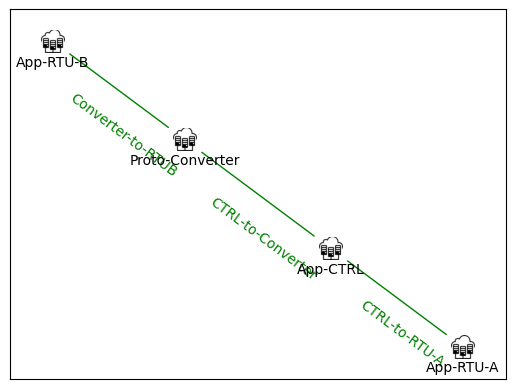

In [9]:
create_plot(net, draw_type='app')
plt.show()

## Summary

You now understand how to:
- Create apps on devices and wire them with end-to-end connections
- Model data-flow direction using `peers` / `producer`
- Check connectivity with `is_connection_possible()`
- Model protocol conversion with converter devices/apps and chained connections
- Define custom link and protocol types

Next we run actual **calculations** on this network — routing paths, reliability metrics, BER, and data volumes.

Next: [04 – Workflow & Analysis](04_workflow_analysis.ipynb)